# Email targeting: uplift and incremental profit

I extend the economics of a frozen T-learner. All amounts are USD, per 10,000 customers. I retain \$30 contribution per buyer and use actual spend to calculate percentage-coupon costs. No model is fitted in this notebook.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from src.data import binary_experiment, load_data, split_data
from src.model import top_mask
from src.profit import policy_value_ipw, profit_difference, sensitivity_grid, uplift_calibration

report = project_dir / "reports"
summary = json.loads((report / "summary.json").read_text())
analysis = json.loads((report / "profit_analysis.json").read_text())
data = pd.read_csv(project_dir / "data/processed/profit_test.csv", index_col="row_id")
policies = pd.read_csv(report / "policy_profit.csv")
samples = pd.read_csv(report / "bootstrap_components.csv")
scores = data[summary["chosen_model"]].to_numpy()
assert hashlib.sha256((project_dir / "models/uplift.joblib").read_bytes()).hexdigest() == analysis["model_sha256"]
assert hashlib.sha256((project_dir / "src/model.py").read_bytes()).hexdigest() == analysis["model_code_sha256"]
assert samples["resample"].nunique() == 1000

## The randomized experiment

I compare Mens E-Mail with No E-Mail. The outcome is a purchase within two weeks. The full experiment gives +0.6805 pp, 95% CI [0.5000; 0.8610] pp. It estimates the effect of email assignment, not coupon size or retention.

,0
treated_n,21307.000000
control_n,21306.000000
treated_orders,267.000000
control_orders,122.000000
treated_rate,0.012531
control_rate,0.005726
effect,0.006805
ci_low,0.005000
ci_high,0.008610
p_value,0.000000


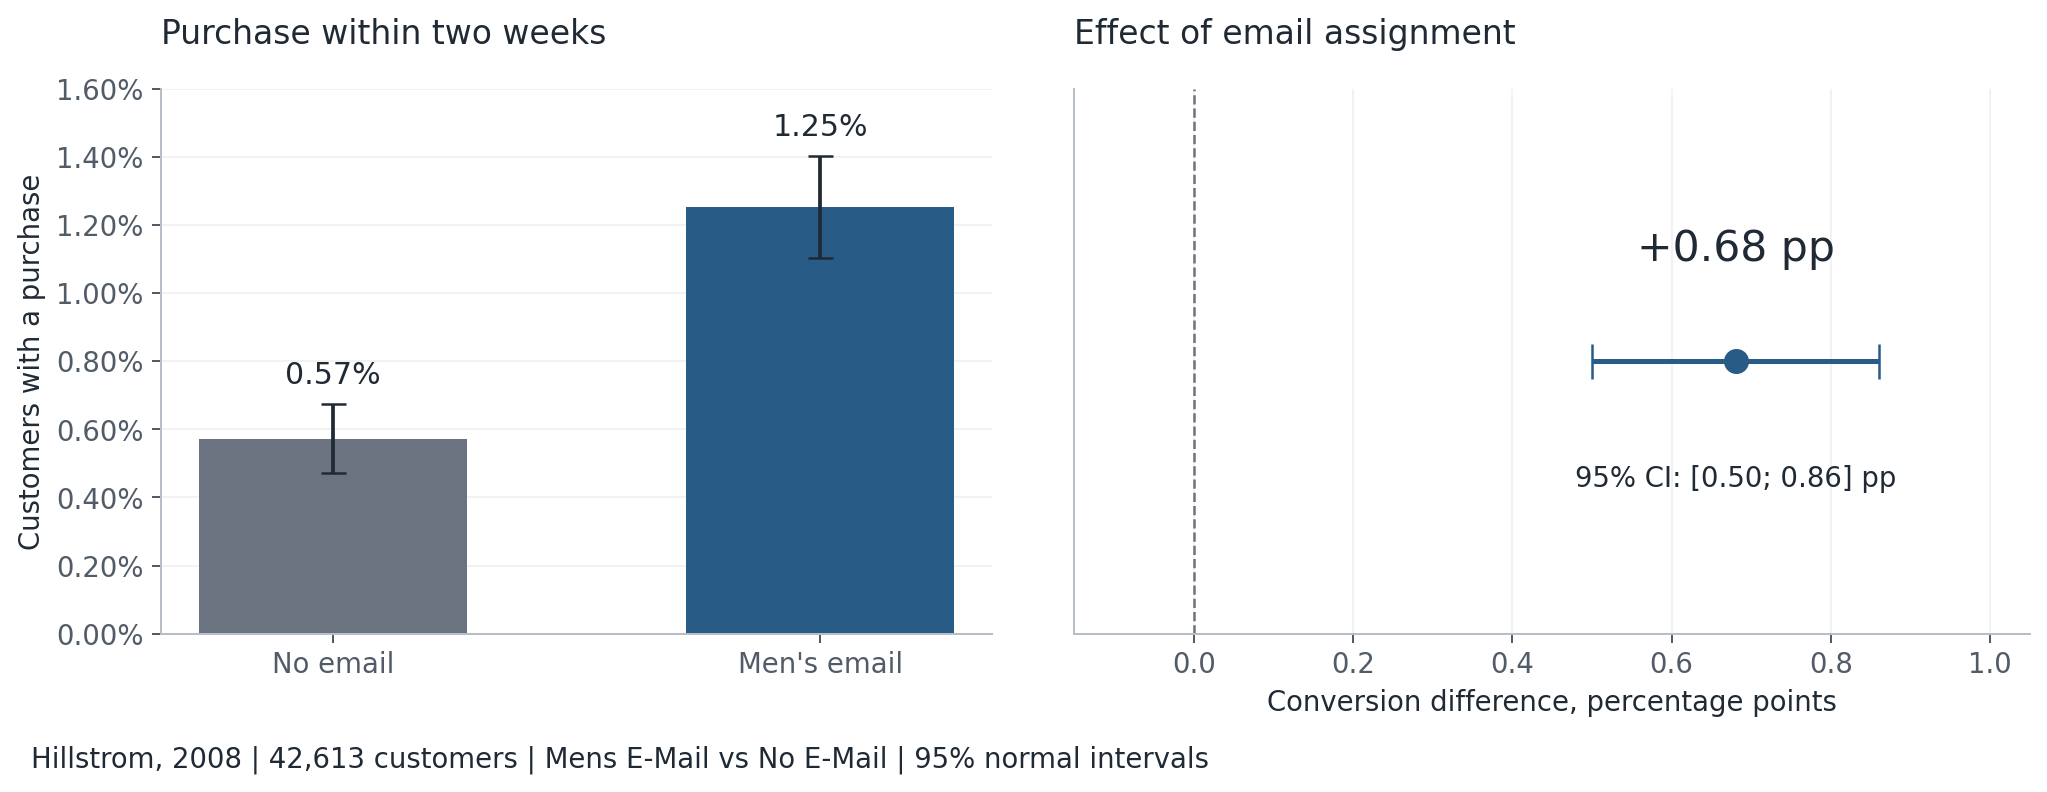

In [2]:
display(pd.DataFrame([summary["ab"]]).T.round(6))
display(Image(filename=str(report / "figures/experiment.png"), width=1050))

## Fixed splits and model

The original split is 60/20/20, stratified by treatment × conversion, seed 42. Observation dates and customer IDs are unavailable. Features use pre-contact information; outcomes are excluded. I keep the original logistic T-learner and top-30% validation policy.

In [3]:
train, validation, test = split_data(binary_experiment(load_data()))
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)
assert data.index.equals(test.index)
np.testing.assert_array_equal(data[["conversion", "treatment", "spend"]], test[["conversion", "treatment", "spend"]])
display(pd.DataFrame(summary["splits"]).T)

,n,orders,treated_n
train,25567,233,12784
validation,8523,78,4262
test,8523,78,4261


## Ranking quality

Logistic Qini changes from 0.0946 on validation to -0.0301 on test. The purchase-probability baseline reaches 0.0498 on test. I retain the validation choice and report the unstable ranking.

,qini,uplift_at_30
logistic,-0.0301,0.0095
forest,-0.0509,0.0061
response,0.0498,0.0089


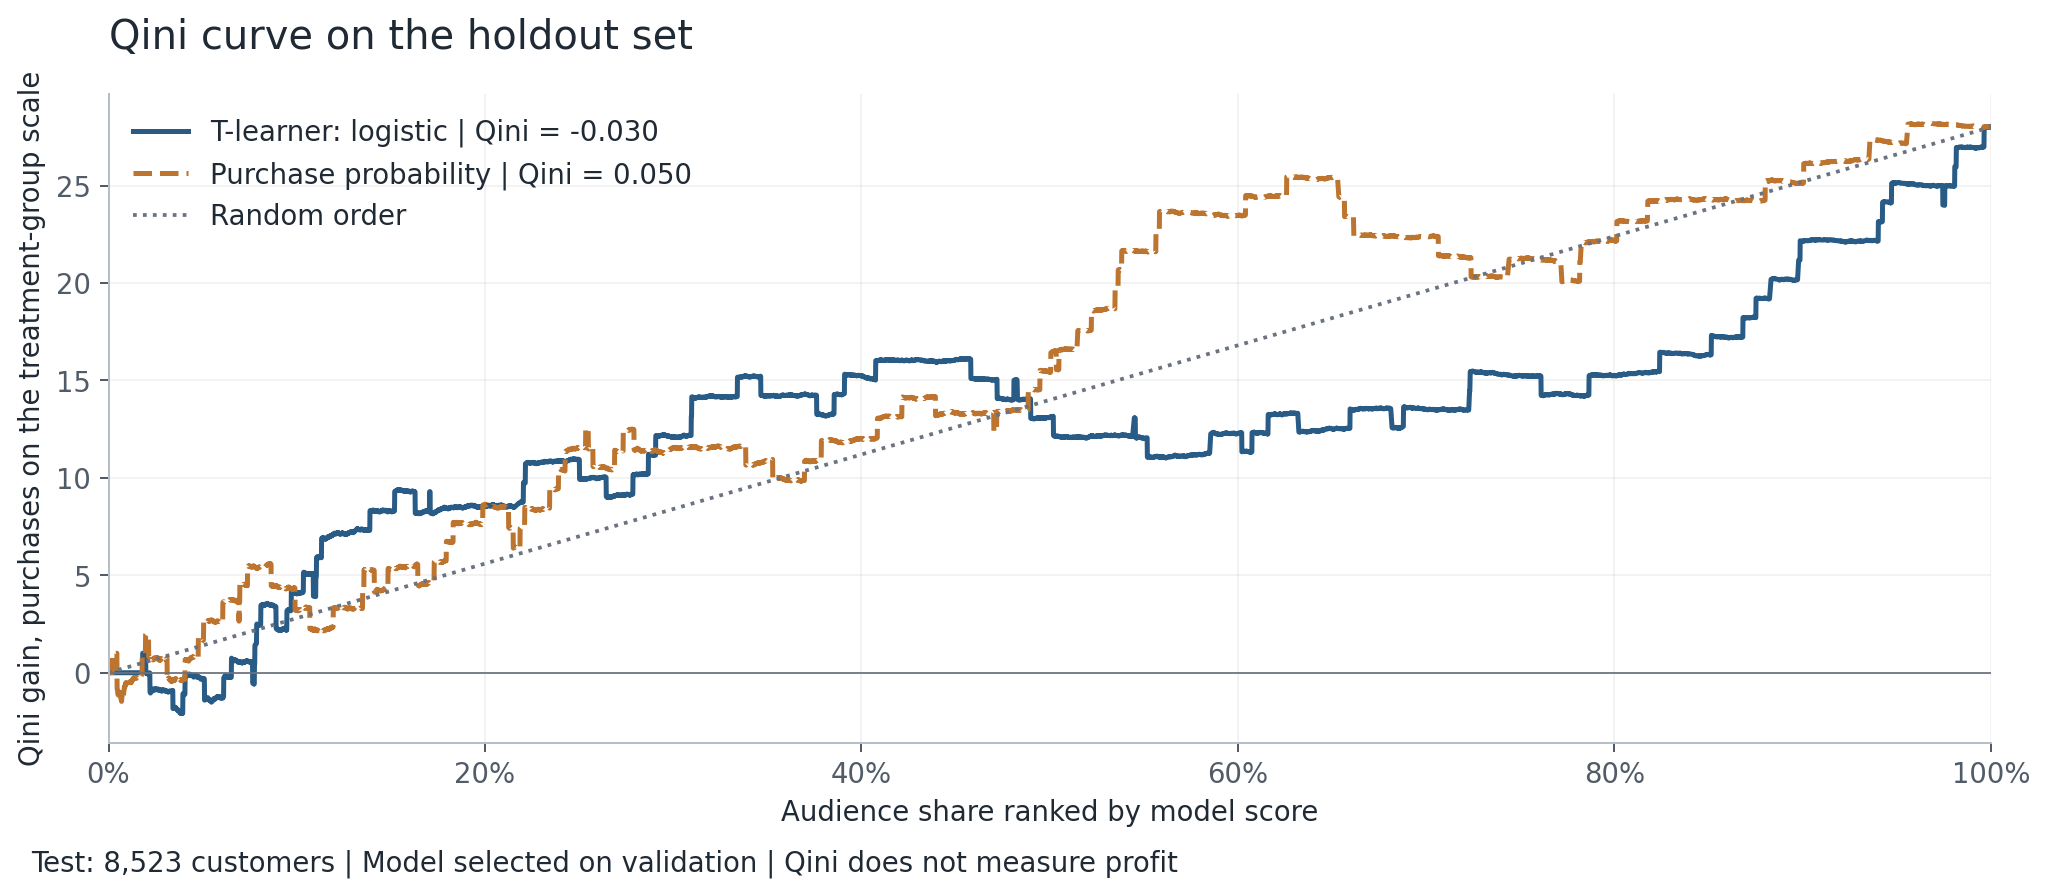

In [4]:
display(pd.DataFrame(summary["test_metrics"]).T.round(4))
display(Image(filename=str(report / "figures/qini.png"), width=1050))

## Normalized IPW profit

The RCT propensity is 0.5 in the binary comparison. I normalize inverse-propensity weights within each selected arm (Hajek). Profit = N × q × [30 × (p1 - p0) - c - d × s1], where s1 is weighted treatment spend per selected customer. A treated buyer pays spend × (1 - d). The coupon reduces the \$30 contribution assumption by its full revenue reduction. With d=0 and c=0 I preserve the existing result.

Intervals use 1,000 IID resamples of test rows. Each draw is shared across fixed policies; audience share is recalculated. No training uncertainty or correction for test-based policy selection is included.

,policy,contacts,extra_orders,profit,ci_low,ci_high
0,no_mail,0.00,0.00,0.00,0.00,0.00
1,mail_all,10000.00,65.73,471.78,-759.39,1616.34
2,top_10,999.65,8.88,116.36,-438.13,673.35
3,top_20,1999.30,19.50,285.00,-419.34,987.14
4,top_30,2998.94,28.53,406.19,-397.57,1221.06
5,top_40,3999.77,36.08,482.34,-406.50,1360.51
6,top_50,4999.41,30.84,175.36,-765.59,1124.43
7,top_60,5999.06,29.00,-29.99,-1003.04,1031.32
8,top_70,6999.88,32.09,-87.35,-1077.65,967.12
9,top_80,7999.53,36.02,-119.21,-1180.78,943.21


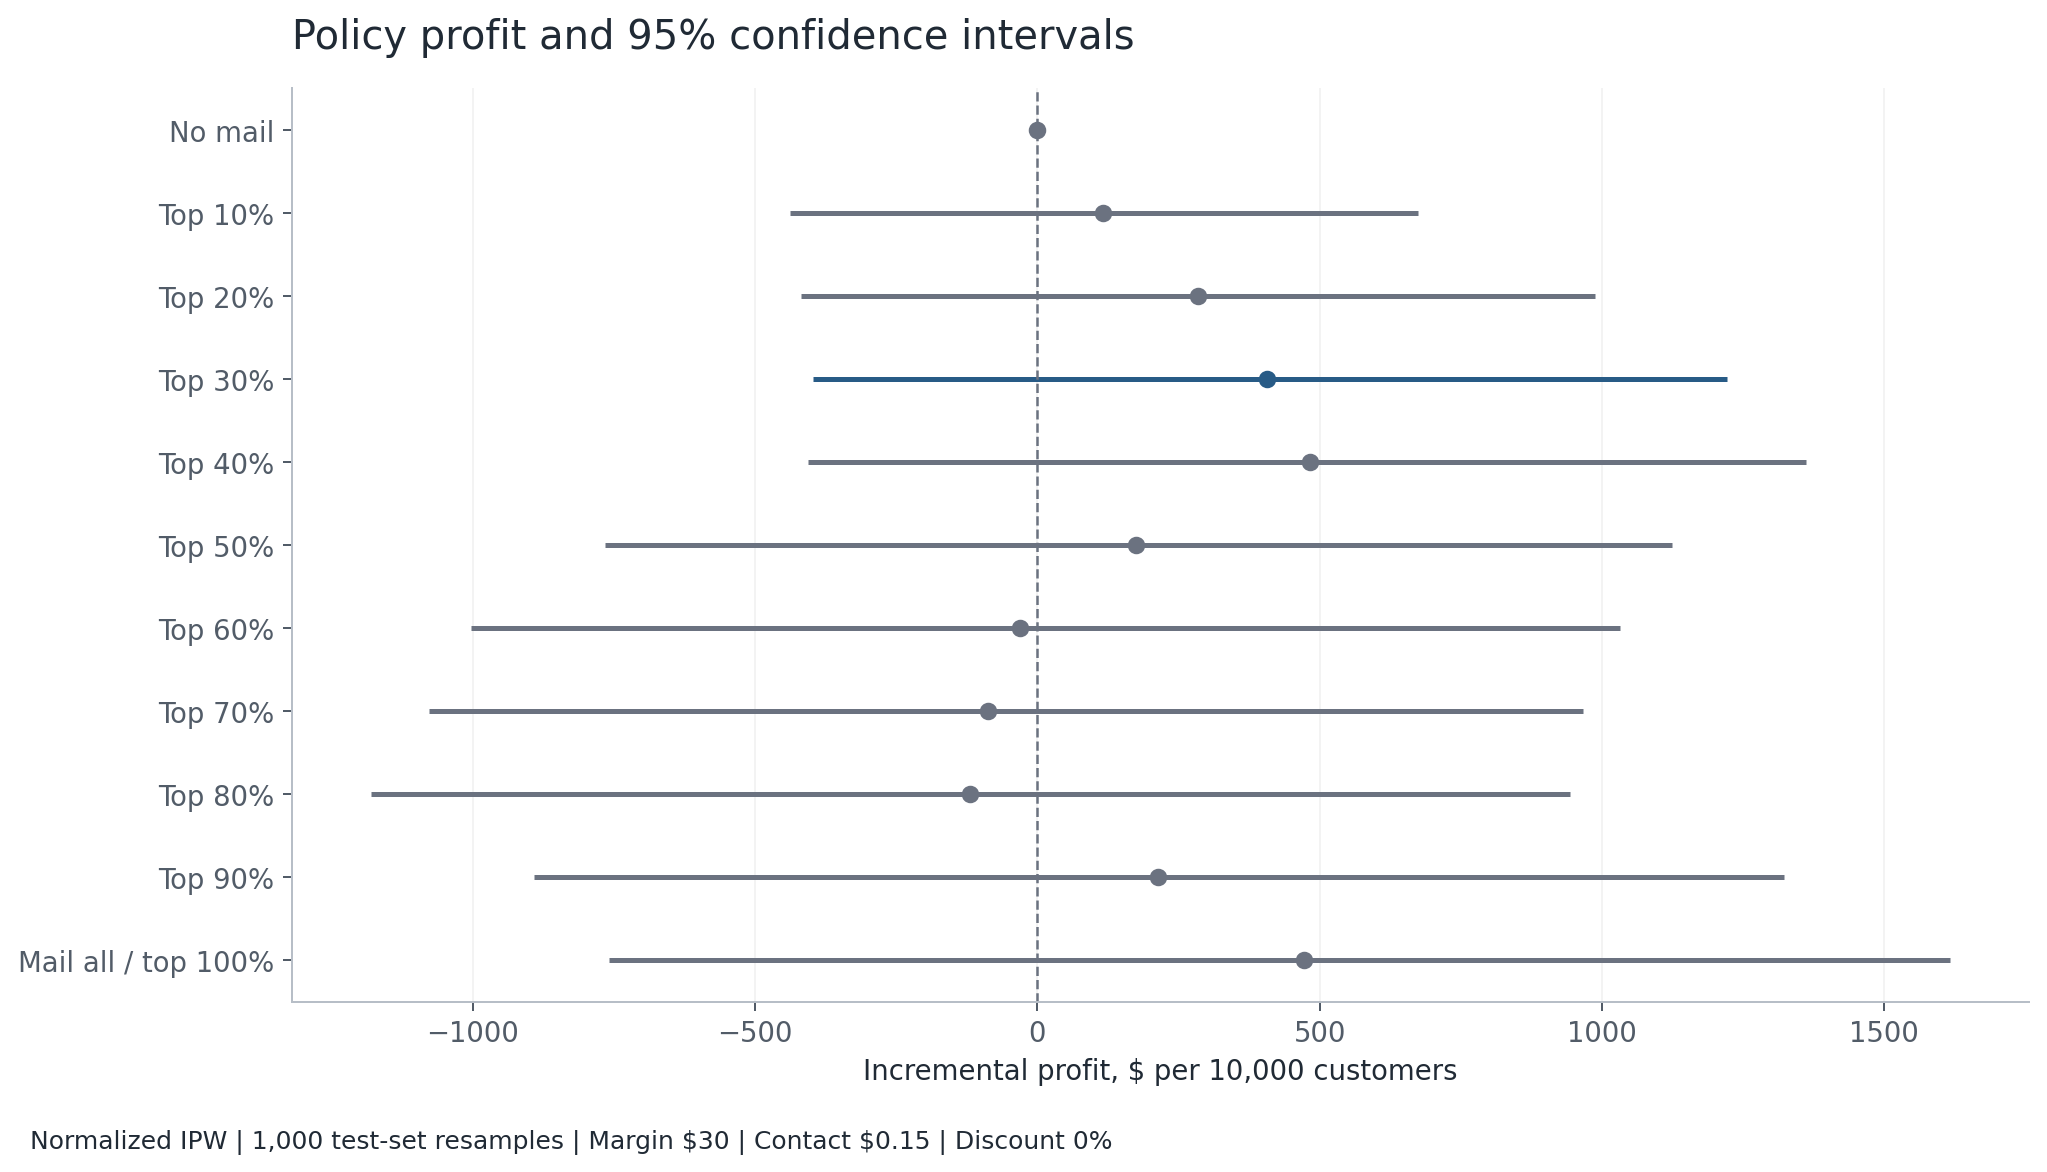

In [5]:
top_30 = policy_value_ipw(data, top_mask(scores, 0.3))
assert np.isclose(top_30["profit"], 406.1874294400996)
assert policy_value_ipw(data, top_mask(scores, 0))["profit"] == 0
assert policy_value_ipw(data, top_mask(scores, 1)) == policy_value_ipw(data, np.ones(len(data), dtype=bool))
display(policies[["policy", "contacts", "extra_orders", "profit", "ci_low", "ci_high"]].round(2))
display(Image(filename=str(report / "policy_profit.png"), width=1050))

### Paired difference

Top-30% minus mail-all is -\$65.59, 95% CI [-\$989.00; \$804.29]. The difference is statistically indistinguishable from zero; this does not establish policy equivalence.

In [6]:
difference_ci = profit_difference(samples)
np.testing.assert_allclose(difference_ci, analysis["top_30_minus_mail_all"]["ci"])
display(pd.DataFrame([analysis["top_30_minus_mail_all"]]))

,profit,ci
0,-65.593781,"[-989.0049367401442, 804.2896215671103]"


## Sensitivity

I evaluate cost \$0.00 to \$0.50 in \$0.05 steps and discount 0% to 30% in 5 pp steps. K ranges from 0% to 100%; K=0% is no mail. Each cell uses the test-set maximum, so this is exploratory rather than fresh validation.

,contact_cost,discount,optimal_k,profit,mail_all_profit,gain_vs_mail_all
7,0.05,0.00,100,1471.78,1471.78,0.00
8,0.05,0.05,100,826.85,826.85,0.00
9,0.05,0.10,100,181.92,181.92,0.00
10,0.05,0.15,0,0.00,-463.01,463.01
11,0.05,0.20,0,0.00,-1107.94,1107.94
12,0.05,0.25,0,0.00,-1752.87,1752.87
13,0.05,0.30,0,0.00,-2397.80,2397.80
21,0.15,0.00,40,482.34,471.78,10.56
22,0.15,0.05,40,96.24,-173.15,269.39
23,0.15,0.10,0,0.00,-818.08,818.08


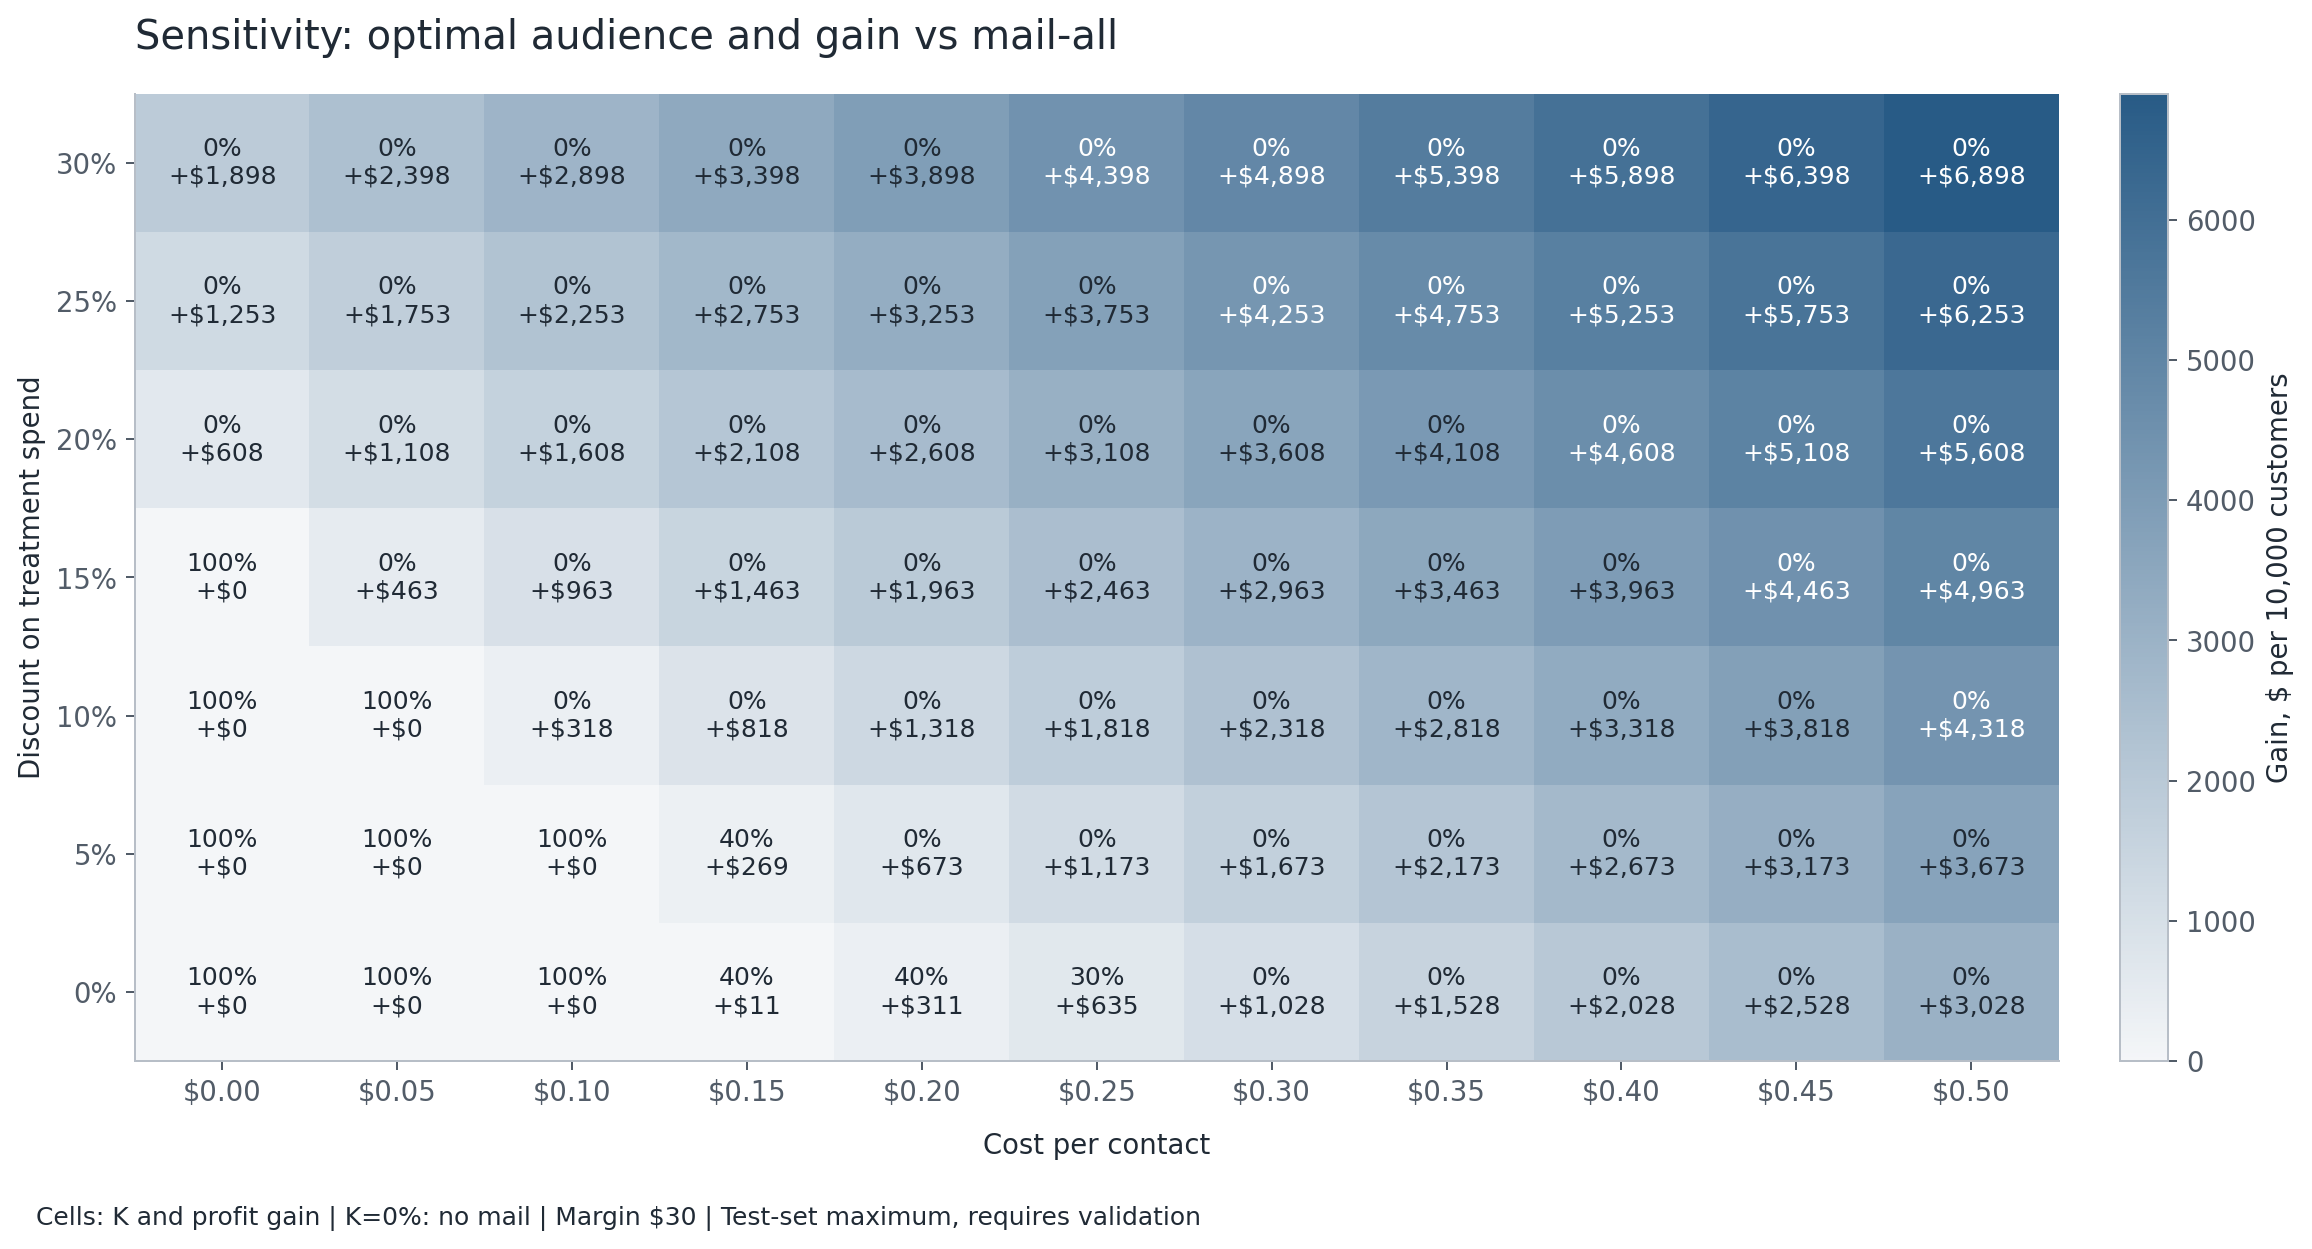

In [7]:
candidates = policies.loc[policies.policy != "mail_all"].reset_index(drop=True)
grid = sensitivity_grid(candidates)
assert len(grid) == 77
display(grid.loc[grid.contact_cost.isin([0.05, 0.15, 0.25])].round(2))
display(Image(filename=str(report / "sensitivity_heatmap.png"), width=1100))

## Break-even boundary

For each d, the maximum mail-all cost is min_k [(B100 - Bk - d × (S100 - Sk)) / (C100 - Ck)]. I include no mail. Without a coupon the boundary is \$0.14824 per contact. At cost \$0.05 the coupon boundary is 11.3870%. These are point-estimate thresholds, not confidence bounds.

,discount,max_contact_cost_for_mail_all,binding_k,mail_all_possible
0,0.00,0.1482,40,True
50,0.05,0.1051,40,True
100,0.10,0.0620,40,True
150,0.15,0.0037,0,True
200,0.20,-0.0608,0,False
250,0.25,-0.1253,0,False
300,0.30,-0.1898,0,False


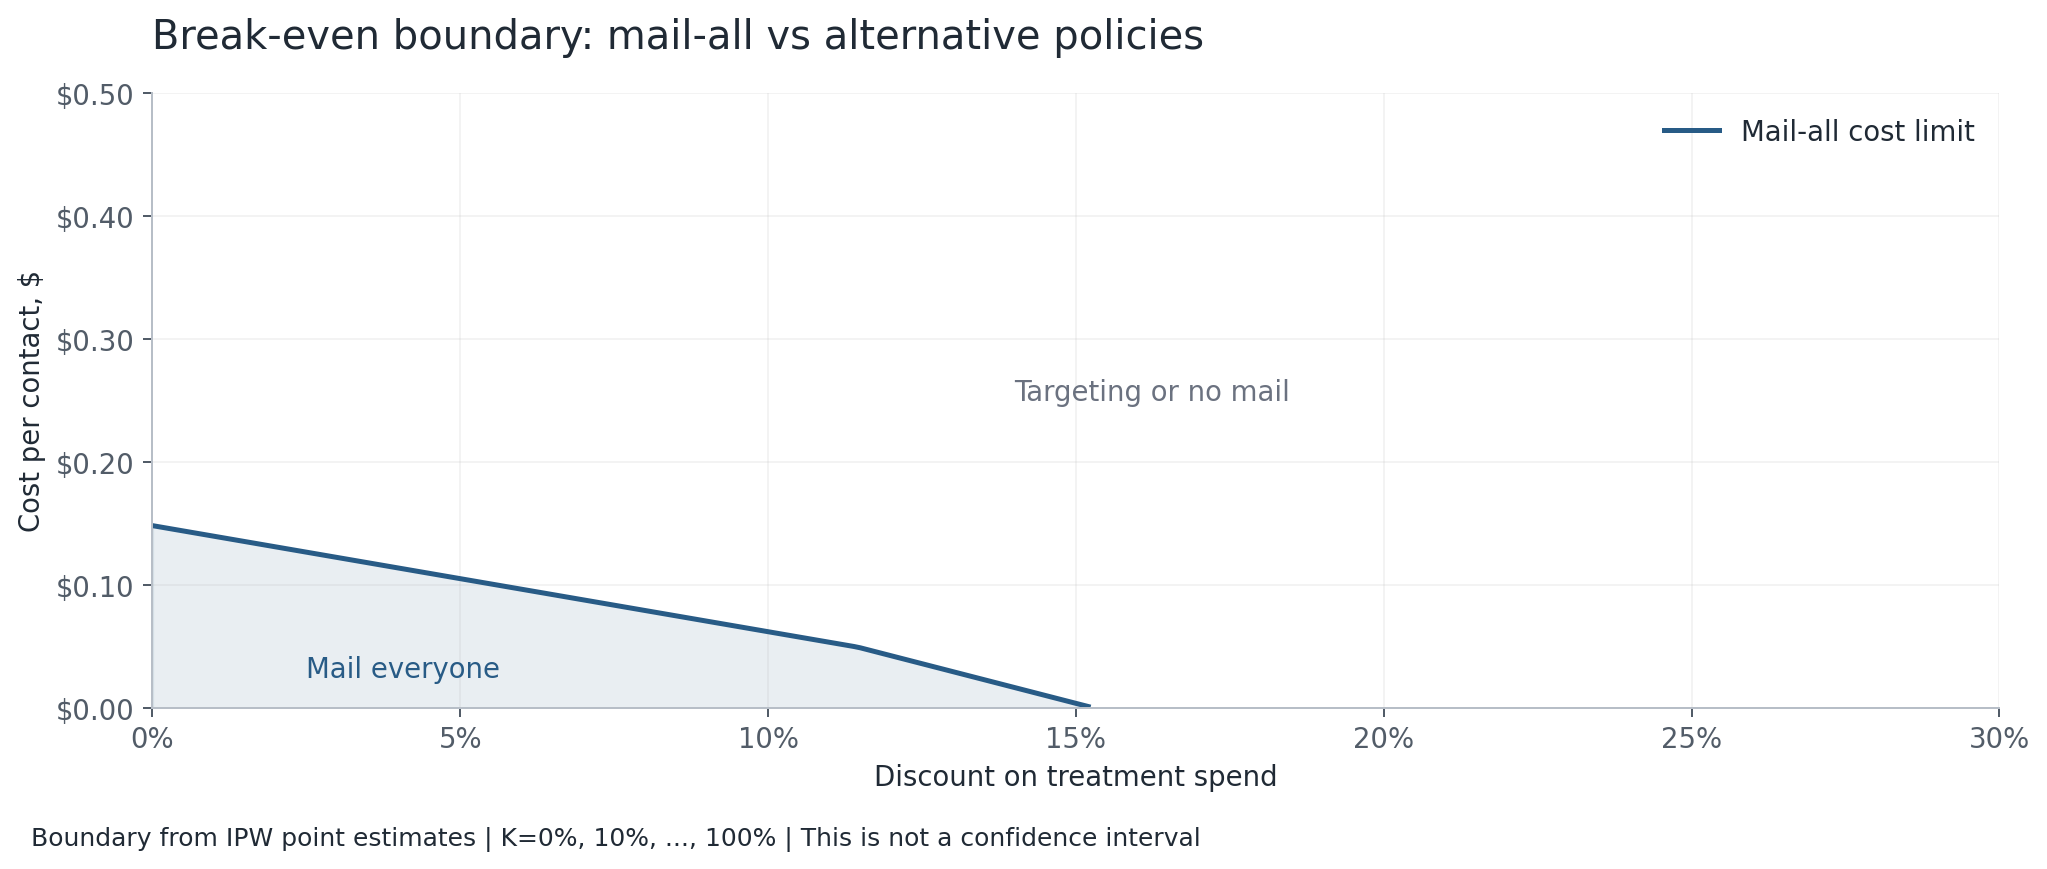

In [8]:
line = pd.read_csv(report / "break_even.csv")
display(line.iloc[::50].round(4))
display(Image(filename=str(report / "break_even.png"), width=1050))

## Uplift calibration

Decile 1 has the highest predicted uplift. I compare the mean score with observed normalized-IPW conversion uplift. Bars show pointwise 95% intervals from 1,000 IID test-row bootstrap samples, seed 42, with deciles and model fixed.

Middle deciles 5 and 6, not the bottom deciles, have negative estimates. Decile 5 is -0.499 pp, 95% CI [-1.720; 0.558]; decile 6 is -0.205 pp, 95% CI [-1.168; 0.779]. Both intervals include zero: the pattern indicates unreliable ranking at this sample size, not an identified harmed segment. A negative CI excluding zero would be necessary to support harm. Intervals exclude training uncertainty and do not adjust for testing ten deciles.

,decile,customers,treated_n,control_n,treated_buyers,control_buyers,predicted_uplift,observed_uplift,negative_observed,observed_ci_low,observed_ci_high,negative_ci_excludes_zero
0,1,852,457,395,11,6,1.3241,0.8880,False,-0.9333,2.8019,False
1,2,852,417,435,7,3,0.9193,0.9890,False,-0.3377,2.5883,False
2,3,852,398,454,5,2,0.7568,0.8158,False,-0.3872,2.1800,False
3,4,853,417,436,5,2,0.6825,0.7403,False,-0.4599,2.0004,False
4,5,852,435,417,2,4,0.6313,-0.4995,True,-1.7202,0.5576,False
5,6,852,415,437,2,3,0.5876,-0.2046,True,-1.1684,0.7790,False
6,7,853,410,443,4,3,0.5452,0.2984,False,-0.8813,1.4960,False
7,8,852,441,411,3,1,0.5022,0.4370,False,-0.4867,1.3895,False
8,9,852,433,419,7,0,0.4526,1.6166,False,0.4796,2.8240,False
9,10,853,438,415,7,1,0.3713,1.3572,False,0.2007,2.6907,False


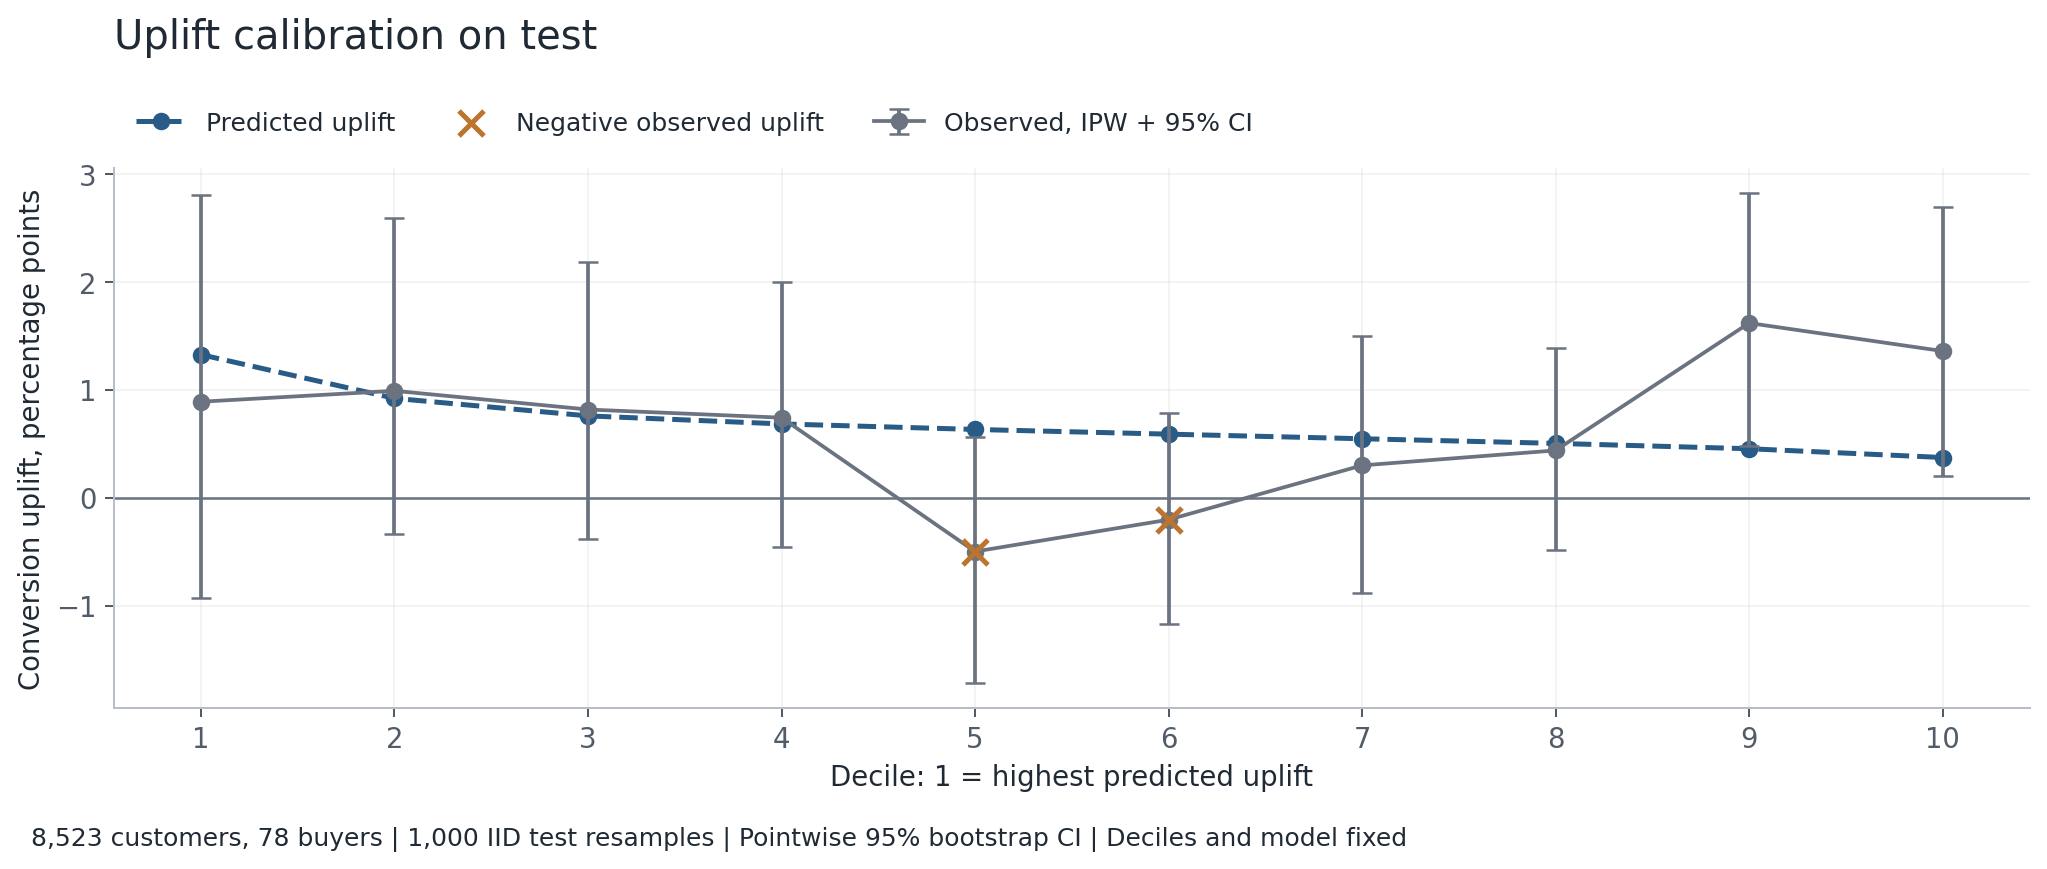

In [9]:
calibration = uplift_calibration(data, scores)
assert calibration.customers.sum() == len(data)
assert calibration.loc[calibration.negative_observed, "decile"].tolist() == [5, 6]
assert not calibration.negative_ci_excludes_zero.any()
calibration[["predicted_uplift", "observed_uplift", "observed_ci_low", "observed_ci_high"]] *= 100
display(calibration.round(4))
display(Image(filename=str(report / "uplift_calibration.png"), width=1050))

## My decision rule

**The rule uses point estimates, not confidence bounds.** Top-30% minus mail-all is -\$66, 95% CI [-\$989; \$804], indistinguishable from zero.

Mail everyone if discount < 11.3% and cost < \$0.05; otherwise target top-K% from the sensitivity calculation. K=0% means no mail; K may still equal 100% outside the conservative region. At default economics the test-set maximum is K=40%, with only \$11 gain over mail-all. I would freeze the policy and test it in a new randomized campaign.

Email was randomized, coupon size was not. These scenarios hold conversion and spend fixed. Returns, actual customer-level contribution and longer-term effects are unavailable. Spend and all assumptions are USD, with no currency conversion or inflation adjustment.

## Next steps

Planned, not implemented:

- A larger or longer randomized test, with the outcome window and sample size set before launch.
- Evaluate `visit` as an exploratory surrogate outcome. Test visits have a 14.45% base rate versus 0.92% for purchases; I would check the relationship to purchases and profit before using it for decisions.
- A DR-learner comparison with cross-fitting and a fresh holdout, using the same profit evaluation.